# MBL Dwn0-Cmp1：波形オートエンコーダーの比較

正常候補データセットの36PVを使用します。末尾のPMData／DODDataは統合し、PV名とbeam_modeを条件入力する共通モデルを各手法で学習します。波形のみの256点AEも基準として比較します。

公式holdoutの42 cycleは、全PVについて学習・検証・閾値校正・PCAのfitから除外済みです。同じcycleや収録アーカイブは独自分割をまたぎません。元波形版は5032点／35221点を入力し、長さで分けるのはバッチだけです。

256点化は、配布サンプルと照合した全区間の線形補間です。間引き版（4点ごと）と区間平均版（4点・16点）は元波形から作ります。PCA＋AEは元波形と256点表現の両方で32・64・128主成分を比較し、逆PCA後の波形で評価します。

上流の正常候補選別には全データのPCA＋kNNが使われています。この依存はholdout cycleを取り除くだけでは解消しないため、公式42件の値はこの制約を付けて解釈します。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
OUTPUT = ROOT / "mbl_autoencoder_comparison"
RUN_TRAINING = False  # 結果閲覧時の再学習を防ぐため、明示的な再実行時だけTrue

if RUN_TRAINING:
    import subprocess, sys
    subprocess.run([sys.executable, str(ROOT / "train_mbl_autoencoder_comparison.py"), "--epochs", "160", "--extend-unfinished"], check=True)


## データ分割と閾値

標準化とPCAは学習側だけでfitします。閾値は独立した校正集合の波形復元誤差から、中央値＋5×標準偏差（ddof=0）で決めます。対象36PVのどれかが閾値を超えるcycleを異常候補とします。

確認済みの異常MBL波形はまだ提供されていないため、異常検出率は未評価です。正常候補の警報率は、確定した誤検知率とは区別します。

In [2]:
config = json.loads((OUTPUT / "configuration.json").read_text())
splits = pd.read_csv(OUTPUT / "sample_splits.csv")
display(pd.DataFrame({"waveforms": config["counts"], "cycles": config["cycles"]}))
assert config["official_holdout_cycle_overlap"] == 0
assert not splits.cycle_id.isin(config["official_holdout_cycle_ids"]).any()
assert splits.groupby("cycle_id")["split"].nunique().max() == 1
assert splits.groupby("source_archive")["split"].nunique().max() == 1


,waveforms,cycles
train,9734,340
validation,1200,44
calibration,1289,59
test,1307,47


## 元波形で比較したMSE

全手法の復元結果を元のサンプル点列に戻し、学習側で固定したPV別スケールでMSEを計算します。256点だけで失われた細かい変化も、この誤差には含まれます。

,method,epochs,best_epoch,epoch_limit_reached,parameters,training_seconds,test_waveforms,test_native_mse,test_candidate_waveforms,test_candidate_rate,test_cycles,test_candidate_cycles,calibration_median,calibration_std,threshold,input_conditions
10,pca_128,0,NaN,False,0,0.000000,1307,0.029379,13,0.009946,47,13,0.004061,0.071141,0.359768,waveform only; per-PV training normalization
8,pca_64,0,NaN,False,0,0.000000,1307,0.031256,15,0.011477,47,15,0.004710,0.073809,0.373757,waveform only; per-PV training normalization
6,pca_32,0,NaN,False,0,0.000000,1307,0.034807,14,0.010712,47,14,0.007023,0.074913,0.381590,waveform only; per-PV training normalization
7,pca_32_ae,160,159.0,True,16244,39.822473,1307,0.036822,14,0.010712,47,14,0.008797,0.076610,0.391849,waveform + PV + beam_mode
9,pca_64_ae,154,144.0,False,26524,37.845738,1307,0.039438,11,0.008416,47,11,0.014153,0.076098,0.394644,waveform + PV + beam_mode
5,mean16,160,160.0,True,100973,75.862872,1307,0.045454,4,0.003060,47,4,0.012481,0.082057,0.422768,waveform + PV + beam_mode
4,mean4,160,160.0,True,100973,85.444266,1307,0.047362,0,0.000000,47,0,0.009830,0.092773,0.473696,waveform + PV + beam_mode
3,decimate4,160,160.0,True,100973,85.781685,1307,0.047583,1,0.000765,47,1,0.010493,0.092987,0.475428,waveform + PV + beam_mode
11,pca_128_ae,109,108.0,False,47084,26.589560,1307,0.055862,6,0.004591,47,6,0.021603,0.093971,0.491459,waveform + PV + beam_mode
2,raw,160,160.0,True,100973,123.444293,1307,0.060603,13,0.009946,47,13,0.017057,0.108017,0.557141,waveform + PV + beam_mode


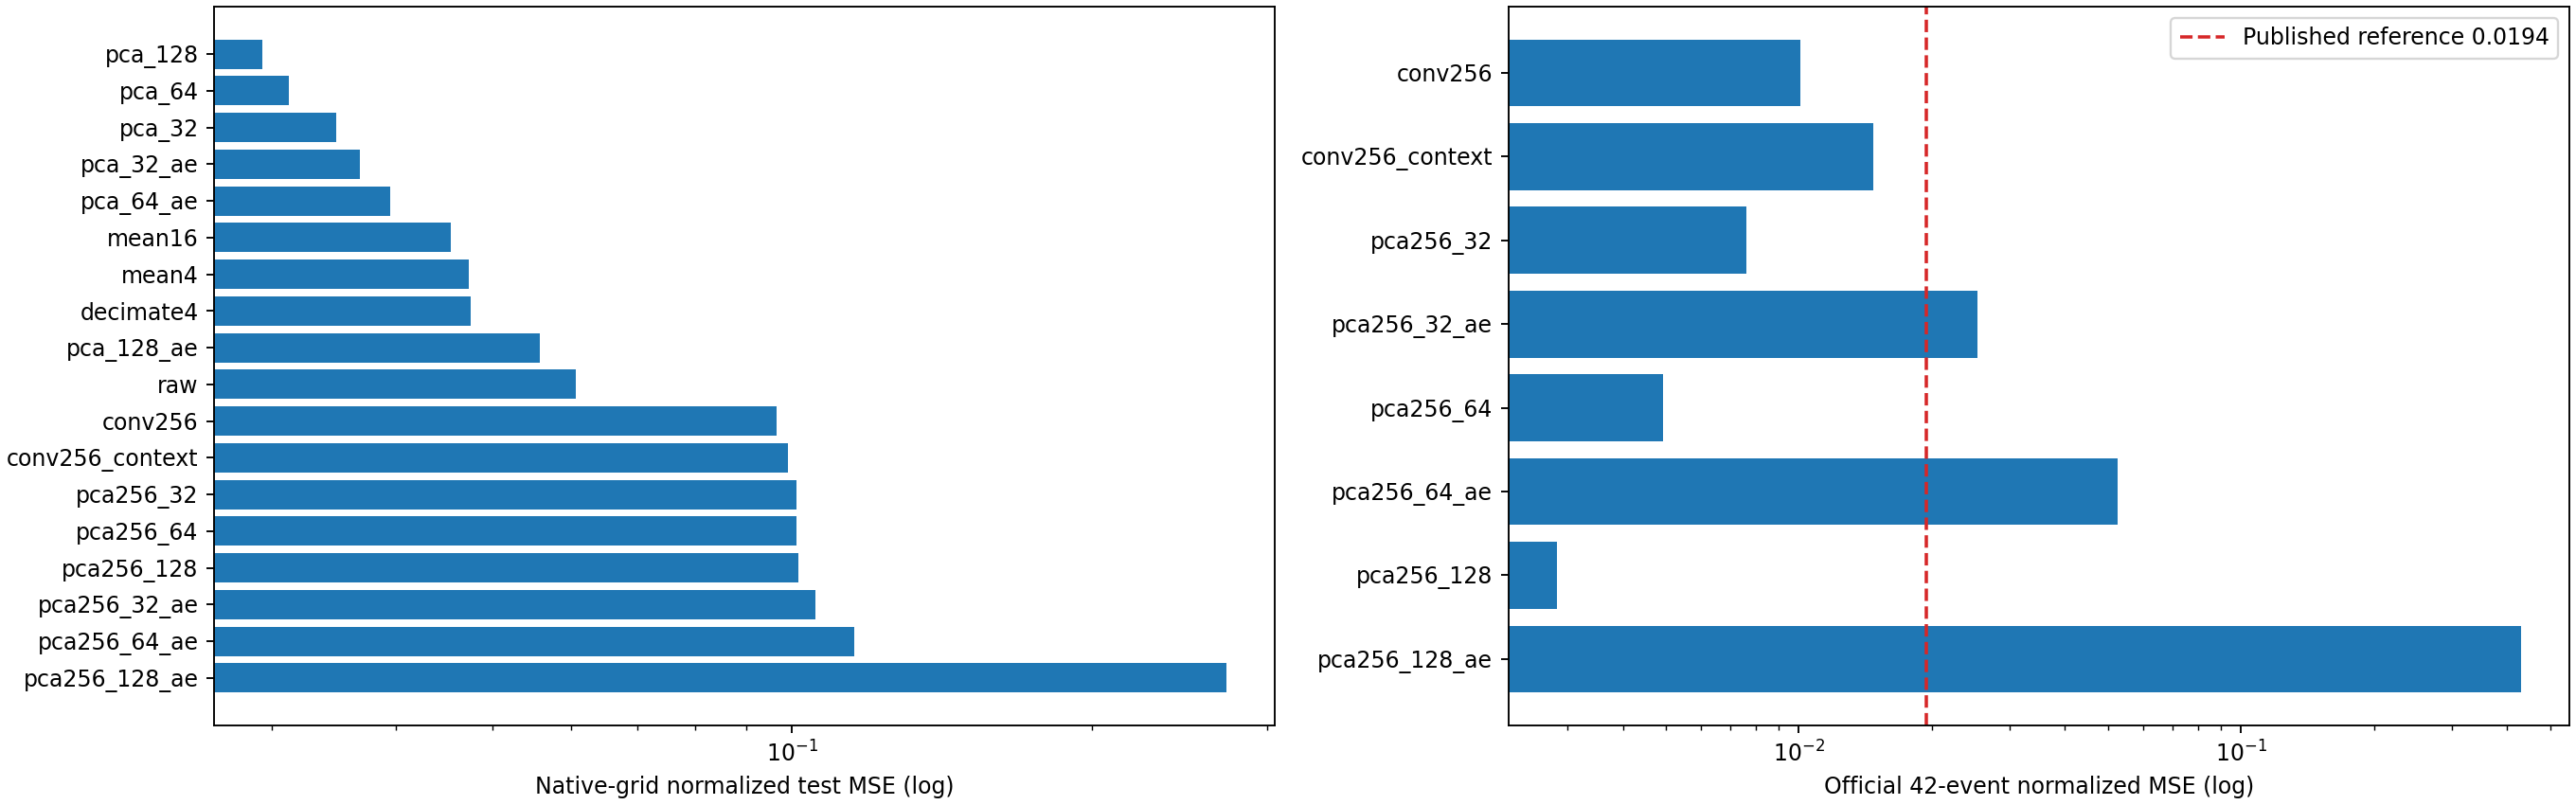

In [3]:
comparison = pd.read_csv(OUTPUT / "comparison.csv")
display(comparison.sort_values("test_native_mse"))
display(Image(filename=str(OUTPUT / "mse_comparison.png")))


## 公式42件の復元MSE

公式の固定42件・公式の正規化とMSE計算を使います。元波形版のPCAを256点にそのまま適用することはせず、256点の表現で学習した手法だけをここで比較します。

`conv256`はPV名・beam_modeを使わず、公式`score.py`を変更せず呼べるアダプターでも照合します。ほかの256点モデルはPV情報による正規化や条件入力を使う拡張評価です。公開規約はこれらの追加メタデータの扱いを明示していません。W&Bへの送信は行いません。

In [4]:
official = pd.read_csv(OUTPUT / "kickoff_score_comparison.csv")
display(official)
validation_path = OUTPUT / "official_score_validation.json"
if validation_path.exists():
    display(json.loads(validation_path.read_text()))


,method,holdout_events,official_holdout_mse,reference_bar,below_reference,metadata_inputs,upstream_normal_selection_independent,kickoff_published_mse,mse_reduction_percent,MBL-010RFC_mse,MBL-090RFC_mse
0,conv256,42,0.010078,0.0194,True,False,False,0.0194,48.051206,0.005557,0.053031
1,conv256_context,42,0.014760,0.0194,True,True,False,0.0194,23.915813,0.005514,0.102602
2,pca256_32,42,0.007597,0.0194,True,True,False,0.0194,60.841563,0.003327,0.048159
3,pca256_32_ae,42,0.025383,0.0194,False,True,False,0.0194,-30.842334,0.021072,0.066343
4,pca256_64,42,0.004931,0.0194,True,True,False,0.0194,74.583348,0.001090,0.041416
5,pca256_64_ae,42,0.052662,0.0194,False,True,False,0.0194,-171.452572,0.033037,0.239098
6,pca256_128,42,0.002832,0.0194,True,True,False,0.0194,85.401933,0.000085,0.028928
7,pca256_128_ae,42,0.430044,0.0194,False,True,False,0.0194,-2116.721165,0.036473,4.168969


{'official_score_py_mean_mse': 0.010078092105686665,
 'recorded_mean_mse': 0.0100780660286545,
 'absolute_difference': 2.6077032163826508e-08,
 'events': 42,
 'waveform_only_adapter': True,
 'metadata_passed_to_adapter': False,
 'kickoff_model_retrained': False,
 'training_executed_by_evaluation': False,
 'native_holdout_models_evaluated': 18,
 'evaluation_cycle_overlap': 0,
 'note': 'Native-input results use additional raw samples and are not the official 256-input MSE benchmark'}

## ラーニングカーブ

学習・検証lossは各モデルが入力する表現に対するMSEです。PCA＋AEの場合は標準化した主成分係数に対するMSEになります。全手法で別途、元波形全体での検証MSEをepochごとに記録しています。

各モデルのCSV、PNG、全曲線のPDFは`mbl_autoencoder_comparison/learning_curves/`および同じ出力フォルダにあります。epoch上限に到達したモデルは収束済みとは断定しません。

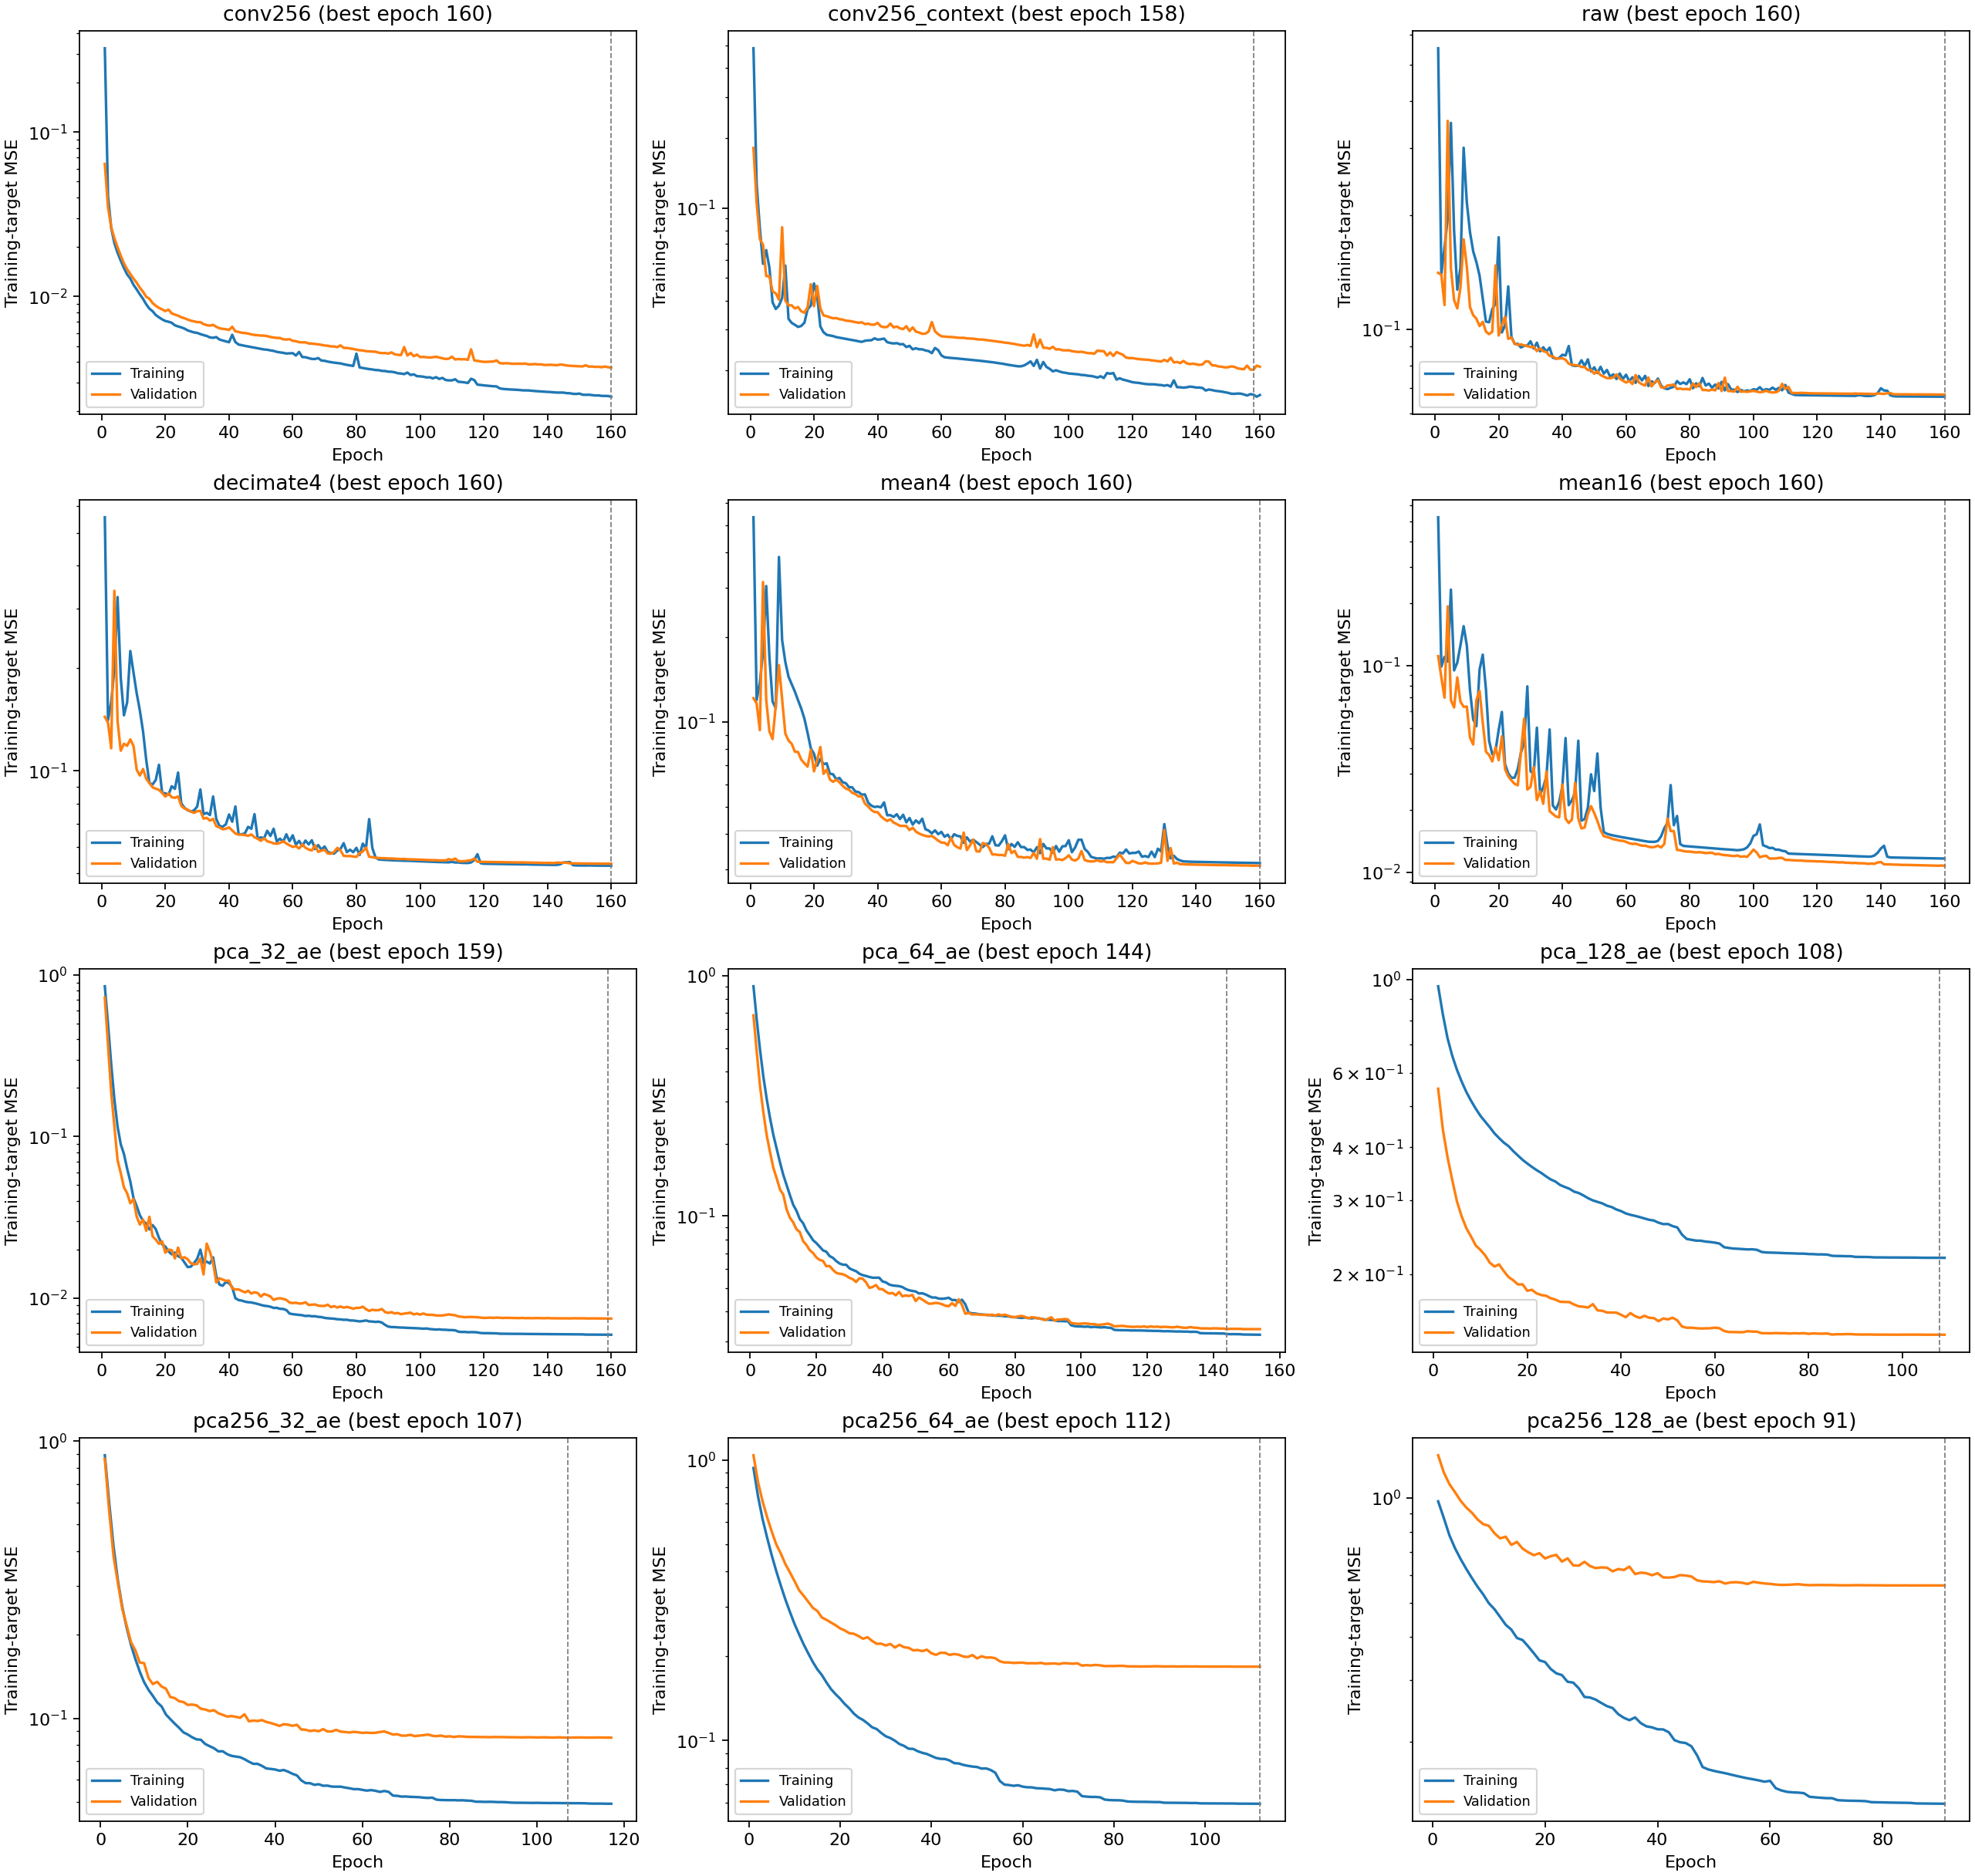

In [5]:
display(Image(filename=str(OUTPUT / "learning_curves" / "all_models.png")))


,epoch,train_mse,validation_mse,validation_waveform_mse,learning_rate,epoch_seconds
0,1,0.551795,0.140831,0.140831,0.001000,1.002857
1,2,0.140189,0.139165,0.139165,0.001000,0.685251
2,3,0.164170,0.115798,0.115798,0.001000,0.685549
3,4,0.196123,0.354823,0.354823,0.001000,0.668187
4,5,0.350490,0.144972,0.144972,0.001000,0.676513
...,...,...,...,...,...,...
155,156,0.066316,0.067190,0.067190,0.000125,0.725704
156,157,0.066318,0.067191,0.067191,0.000125,0.721779
157,158,0.066307,0.067156,0.067156,0.000125,0.716371
158,159,0.066283,0.067164,0.067164,0.000125,0.719643


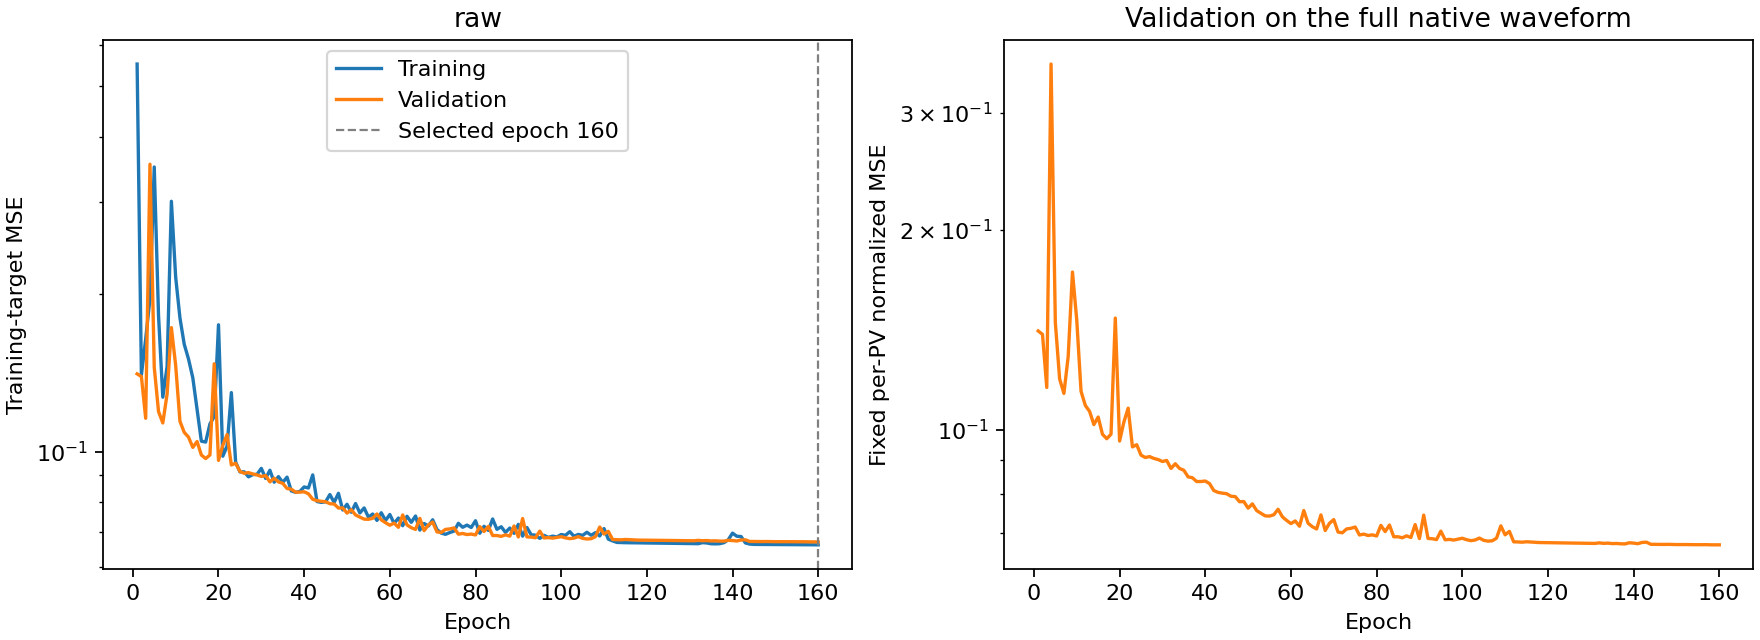

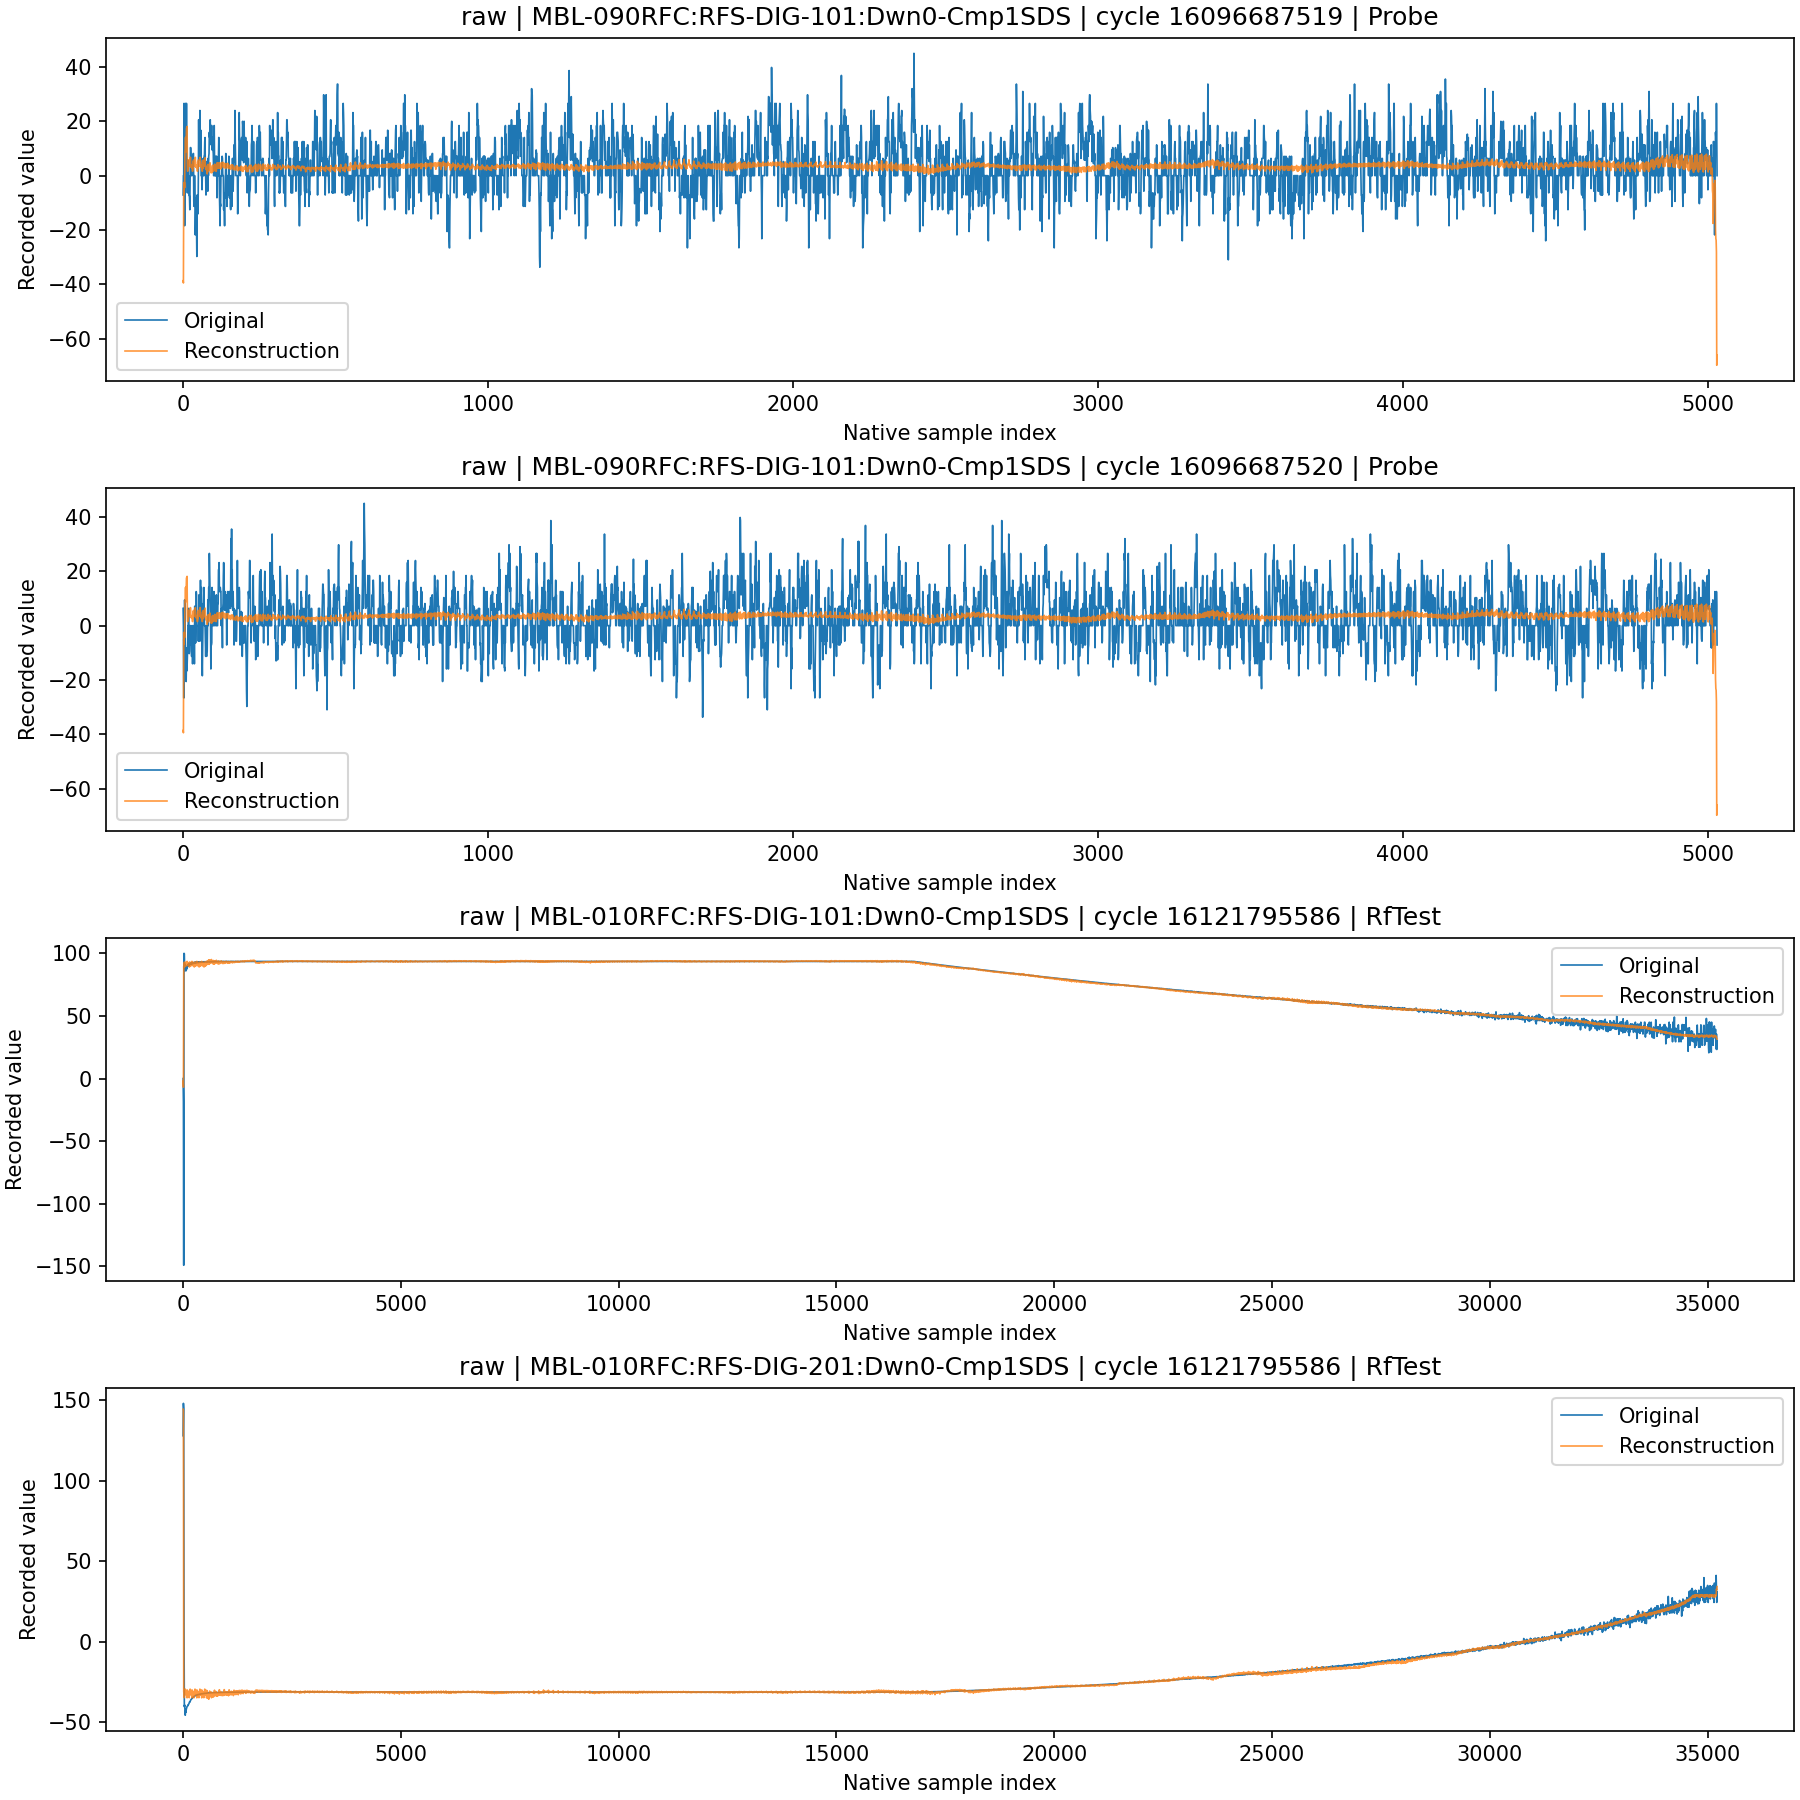

In [6]:
SELECTED_METHOD = "raw"  # conv256, conv256_context, decimate4, mean4, mean16, pca_32_aeなど
history_path = OUTPUT / f"{SELECTED_METHOD}_history.csv"
if history_path.exists():
    display(pd.read_csv(history_path))
    display(Image(filename=str(OUTPUT / "learning_curves" / f"{SELECTED_METHOD}.png")))
display(Image(filename=str(OUTPUT / f"{SELECTED_METHOD}_reconstructions.png")))


## 誤差分布・cycle判定

閾値と各波形の復元誤差を残し、cycle単位の候補と原因候補PVを出力します。異常cycleというラベルだけから、そのcycleの全PVを異常とは扱いません。

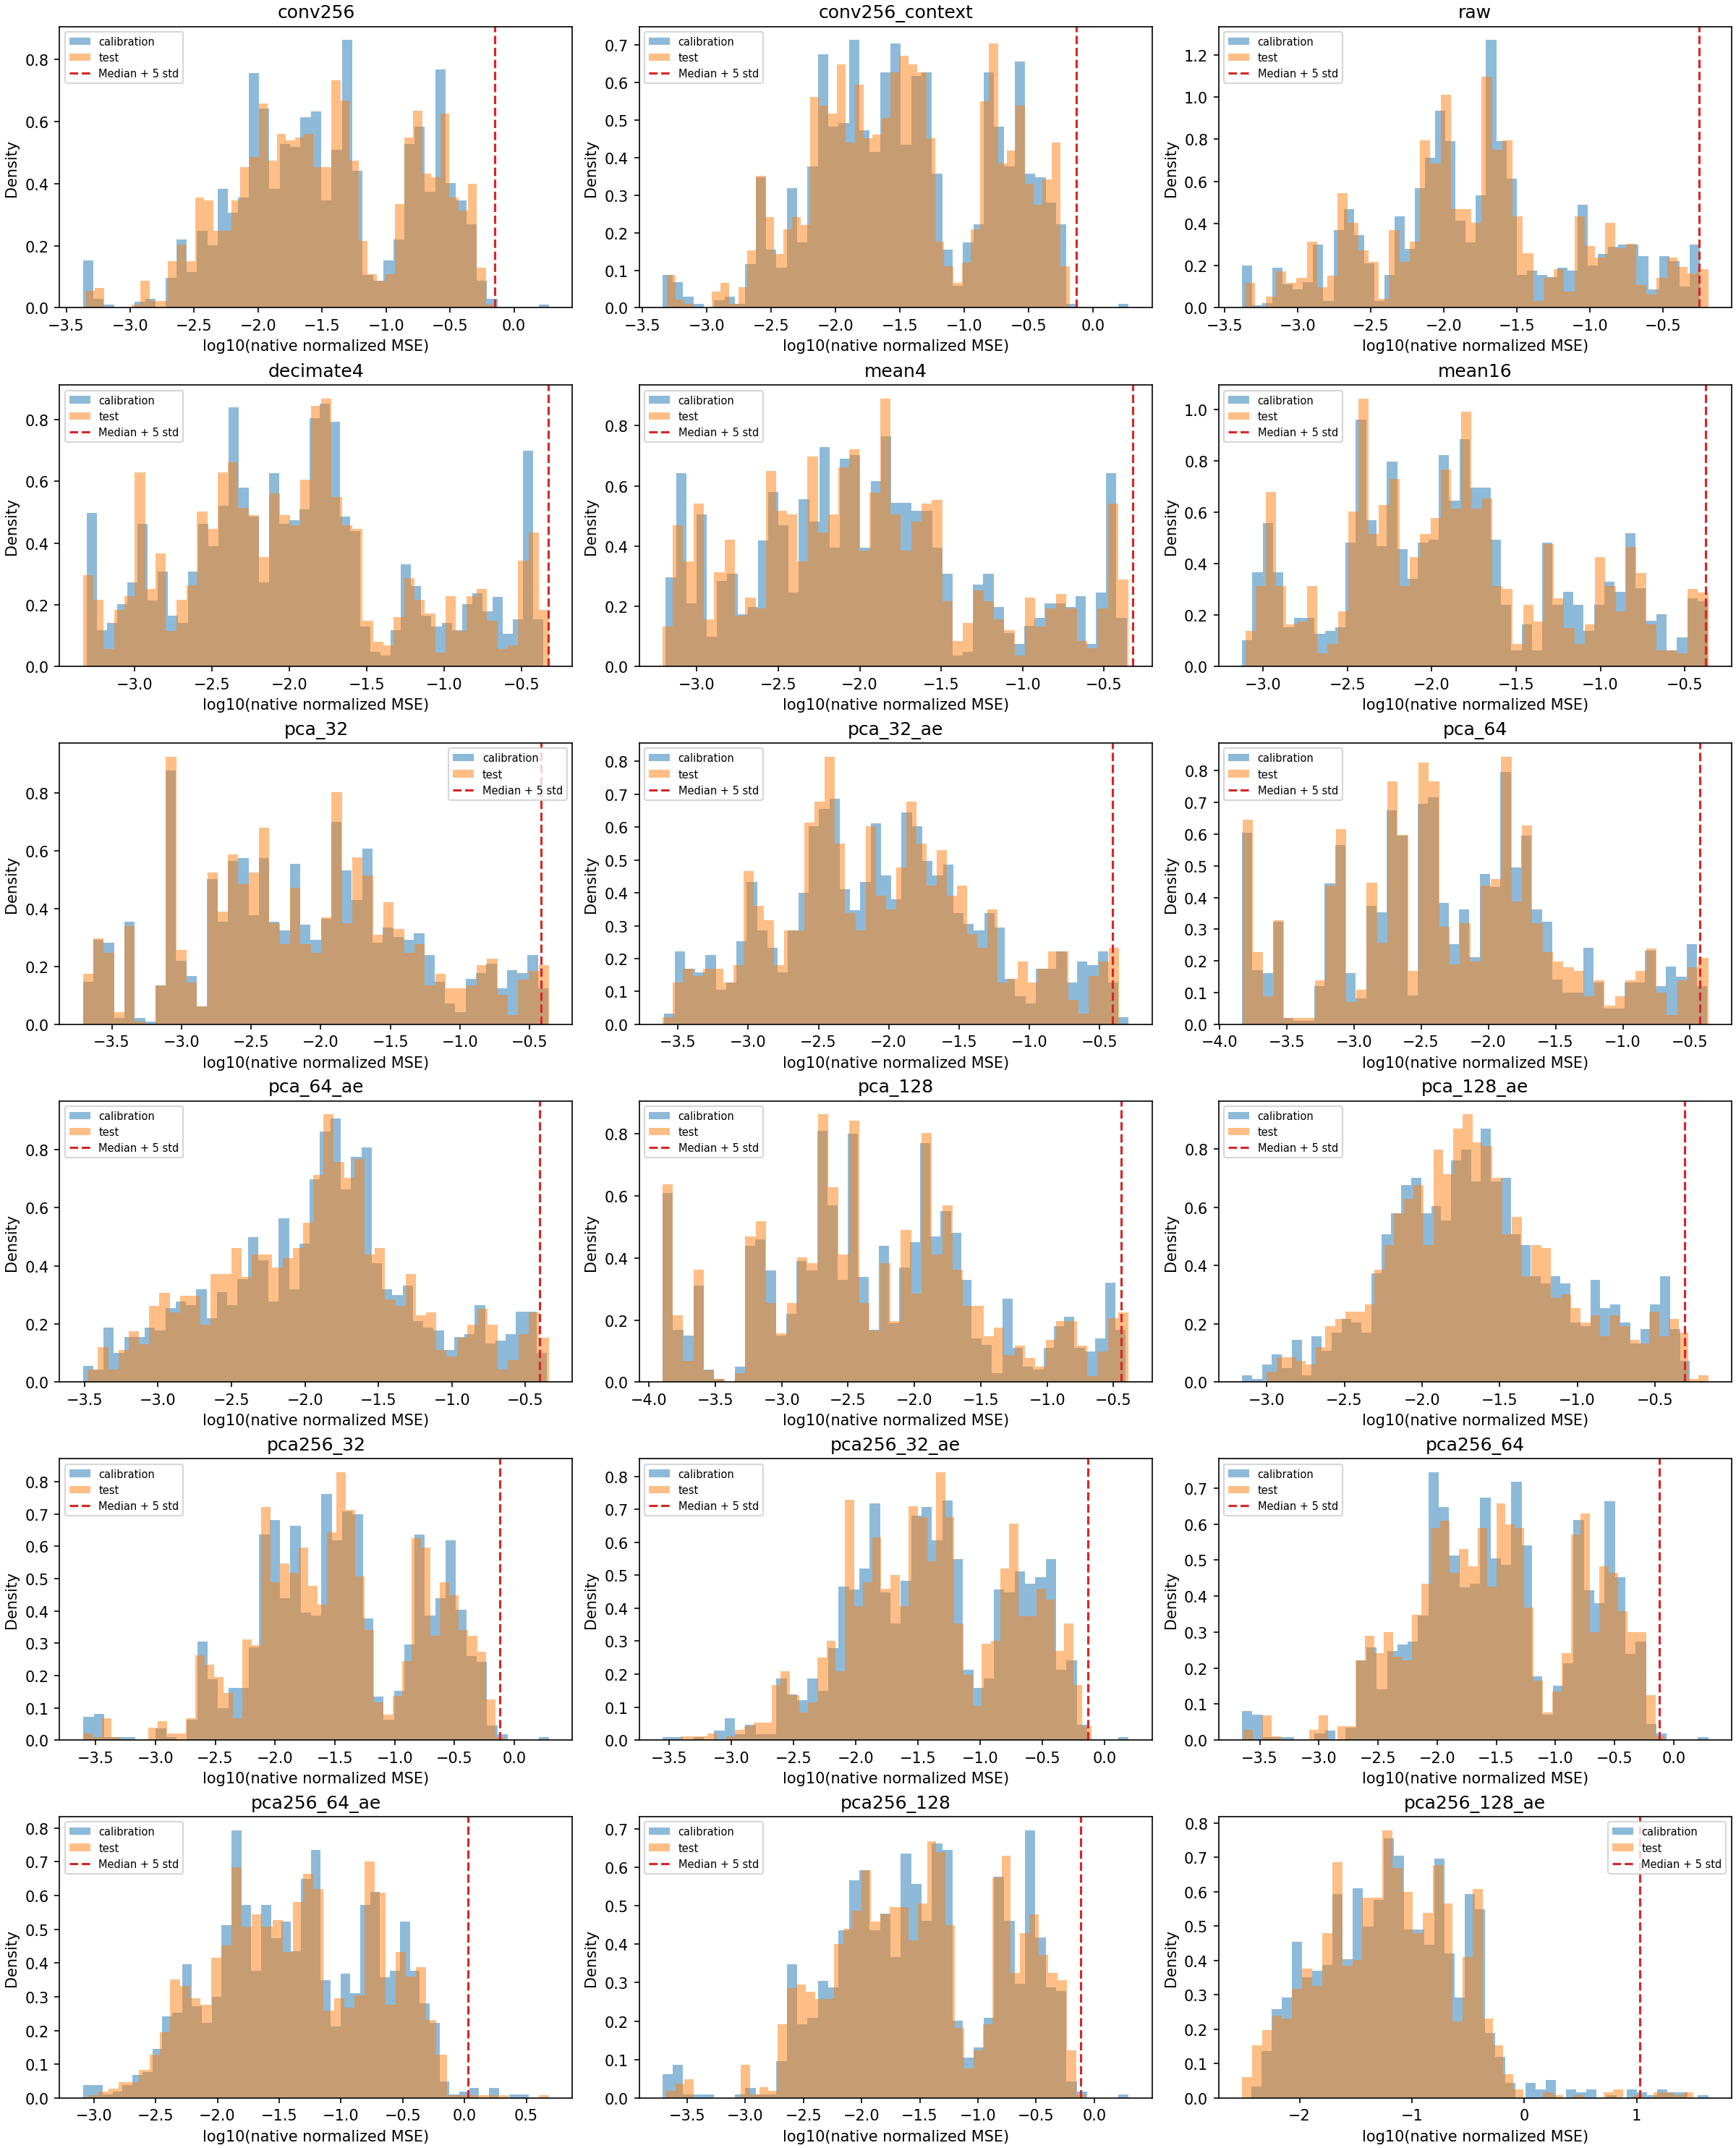

,cycle_id,cycle_score,threshold,anomaly_candidate,status,observed_pvs,scored_pvs,unscored_waveforms,candidate_pv_count,candidate_pvs,highest_score_pv,top5_pvs,cycle_ts,beam_mode,split
46,16098677156,0.718864,0.557141,True,anomaly_candidate,4,4,0,1,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS|MBL-010RFC...,2026-06-09 23:39:20.699742256+00:00,Probe,train
47,16098677170,0.697203,0.557141,True,anomaly_candidate,4,4,0,1,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS|MBL-010RFC...,2026-06-09 23:39:21.699742210+00:00,Probe,train
48,16098677184,0.708839,0.557141,True,anomaly_candidate,4,4,0,1,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS|MBL-010RFC...,2026-06-09 23:39:22.699742165+00:00,Probe,train
49,16098677198,0.763686,0.557141,True,anomaly_candidate,4,4,0,1,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS|MBL-010RFC...,2026-06-09 23:39:23.699742119+00:00,Probe,train
50,16098677212,0.764836,0.557141,True,anomaly_candidate,4,4,0,1,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS|MBL-010RFC...,2026-06-09 23:39:24.699742074+00:00,Probe,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
484,16123106084,0.634745,0.557141,True,anomaly_candidate,36,36,0,1,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS|MBL-020RFC...,2026-06-30 04:20:33.055134834+00:00,RfTest,train
485,16123106098,0.607544,0.557141,True,anomaly_candidate,36,36,0,1,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS|MBL-020RFC...,2026-06-30 04:20:34.055134788+00:00,RfTest,train
486,16123106112,0.657600,0.557141,True,anomaly_candidate,36,36,0,1,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS|MBL-020RFC...,2026-06-30 04:20:35.055134743+00:00,RfTest,train
488,16123106140,0.578217,0.557141,True,anomaly_candidate,36,36,0,1,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS|MBL-020RFC...,2026-06-30 04:20:37.055134652+00:00,RfTest,train


,original_row,cycle_id,cycle_ts,pv,source_pv,beam_mode,source_archive,length,split,score,diagnosis_pv,waveform_score,threshold,pv_anomaly_candidate
0,1443,16098677156,2026-06-09 23:39:20.699742256+00:00,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS-PMData,Probe,/lustre/work/pdl18409/shared/data/anomaly-dete...,35221,train,0.718864,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS,0.718864,0.557141,True
1,1467,16098677170,2026-06-09 23:39:21.699742210+00:00,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS-PMData,Probe,/lustre/work/pdl18409/shared/data/anomaly-dete...,35221,train,0.697203,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS,0.697203,0.557141,True
2,1491,16098677184,2026-06-09 23:39:22.699742165+00:00,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS-PMData,Probe,/lustre/work/pdl18409/shared/data/anomaly-dete...,35221,train,0.708839,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS,0.708839,0.557141,True
3,1515,16098677198,2026-06-09 23:39:23.699742119+00:00,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS-PMData,Probe,/lustre/work/pdl18409/shared/data/anomaly-dete...,35221,train,0.763686,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS,0.763686,0.557141,True
4,1539,16098677212,2026-06-09 23:39:24.699742074+00:00,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS-PMData,Probe,/lustre/work/pdl18409/shared/data/anomaly-dete...,35221,train,0.764836,MBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS,0.764836,0.557141,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
165,215830,16123106084,2026-06-30 04:20:33.055134834+00:00,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS-PMData,RfTest,/lustre/work/pdl18409/shared/data/anomaly-dete...,35221,train,0.634745,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS,0.634745,0.557141,True
166,216327,16123106098,2026-06-30 04:20:34.055134788+00:00,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS-PMData,RfTest,/lustre/work/pdl18409/shared/data/anomaly-dete...,35221,train,0.607544,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS,0.607544,0.557141,True
167,216824,16123106112,2026-06-30 04:20:35.055134743+00:00,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS-PMData,RfTest,/lustre/work/pdl18409/shared/data/anomaly-dete...,35221,train,0.657600,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS,0.657600,0.557141,True
168,217818,16123106140,2026-06-30 04:20:37.055134652+00:00,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS-PMData,RfTest,/lustre/work/pdl18409/shared/data/anomaly-dete...,35221,train,0.578217,MBL-020RFC:RFS-DIG-101:Dwn0-Cmp1SDS,0.578217,0.557141,True


In [7]:
display(Image(filename=str(OUTPUT / "score_distributions.png")))
cycles = pd.read_csv(OUTPUT / f"{SELECTED_METHOD}_cycle_predictions.csv")
display(cycles.loc[cycles.anomaly_candidate.eq(True)])
display(pd.read_csv(OUTPUT / f"{SELECTED_METHOD}_candidate_pvs.csv"))


## 保存済みモデルの利用

`predict_mbl_autoencoder.py`の`MBLDetector`で、新しい同じ長さの波形バッチを復元できます。PV名・beam_modeを併せて渡します。`OfficialWaveformAdapter`は波形のみの256点モデル用です。

In [8]:
# 学習済みモデルを読み込む例（学習はしません）
# from predict_mbl_autoencoder import MBLDetector
# detector = MBLDetector(OUTPUT, method=SELECTED_METHOD)
# scores, reconstructions = detector.predict(waveforms, pv_names, beam_modes)
# candidates = scores > detector.threshold


## 評価用42件の元波形を使った比較

すべての手法を同じ42件のPV波形で評価します。元波形入力モデルは追加のサンプル点を使うため、公式の256点入力だけのベンチマークとは区別します。この表の元波形MSEと、kickoff掲載値0.0194は異なるスケールの指標です。

kickoffモデルは再学習せず、公式256点MSEの表で掲載値0.0194と比較します。

,method,events,input_grid,mean_native_normalized_mse,candidate_waveforms,threshold,official_256_input_compatible
0,conv256,42,256,0.042528,0,0.704273,True
1,conv256_context,42,256,0.065240,0,0.744164,True
2,raw,42,native (5032/35221),0.036030,0,0.557141,False
3,decimate4,42,native (5032/35221),0.039507,0,0.475428,False
4,mean4,42,native (5032/35221),0.041879,0,0.473696,False
5,mean16,42,native (5032/35221),0.044667,0,0.422768,False
6,pca_32,42,native (5032/35221),0.034890,0,0.381590,False
7,pca_32_ae,42,native (5032/35221),0.036401,0,0.391849,False
8,pca_64,42,native (5032/35221),0.034015,0,0.373757,False
9,pca_64_ae,42,native (5032/35221),0.040154,0,0.394644,False


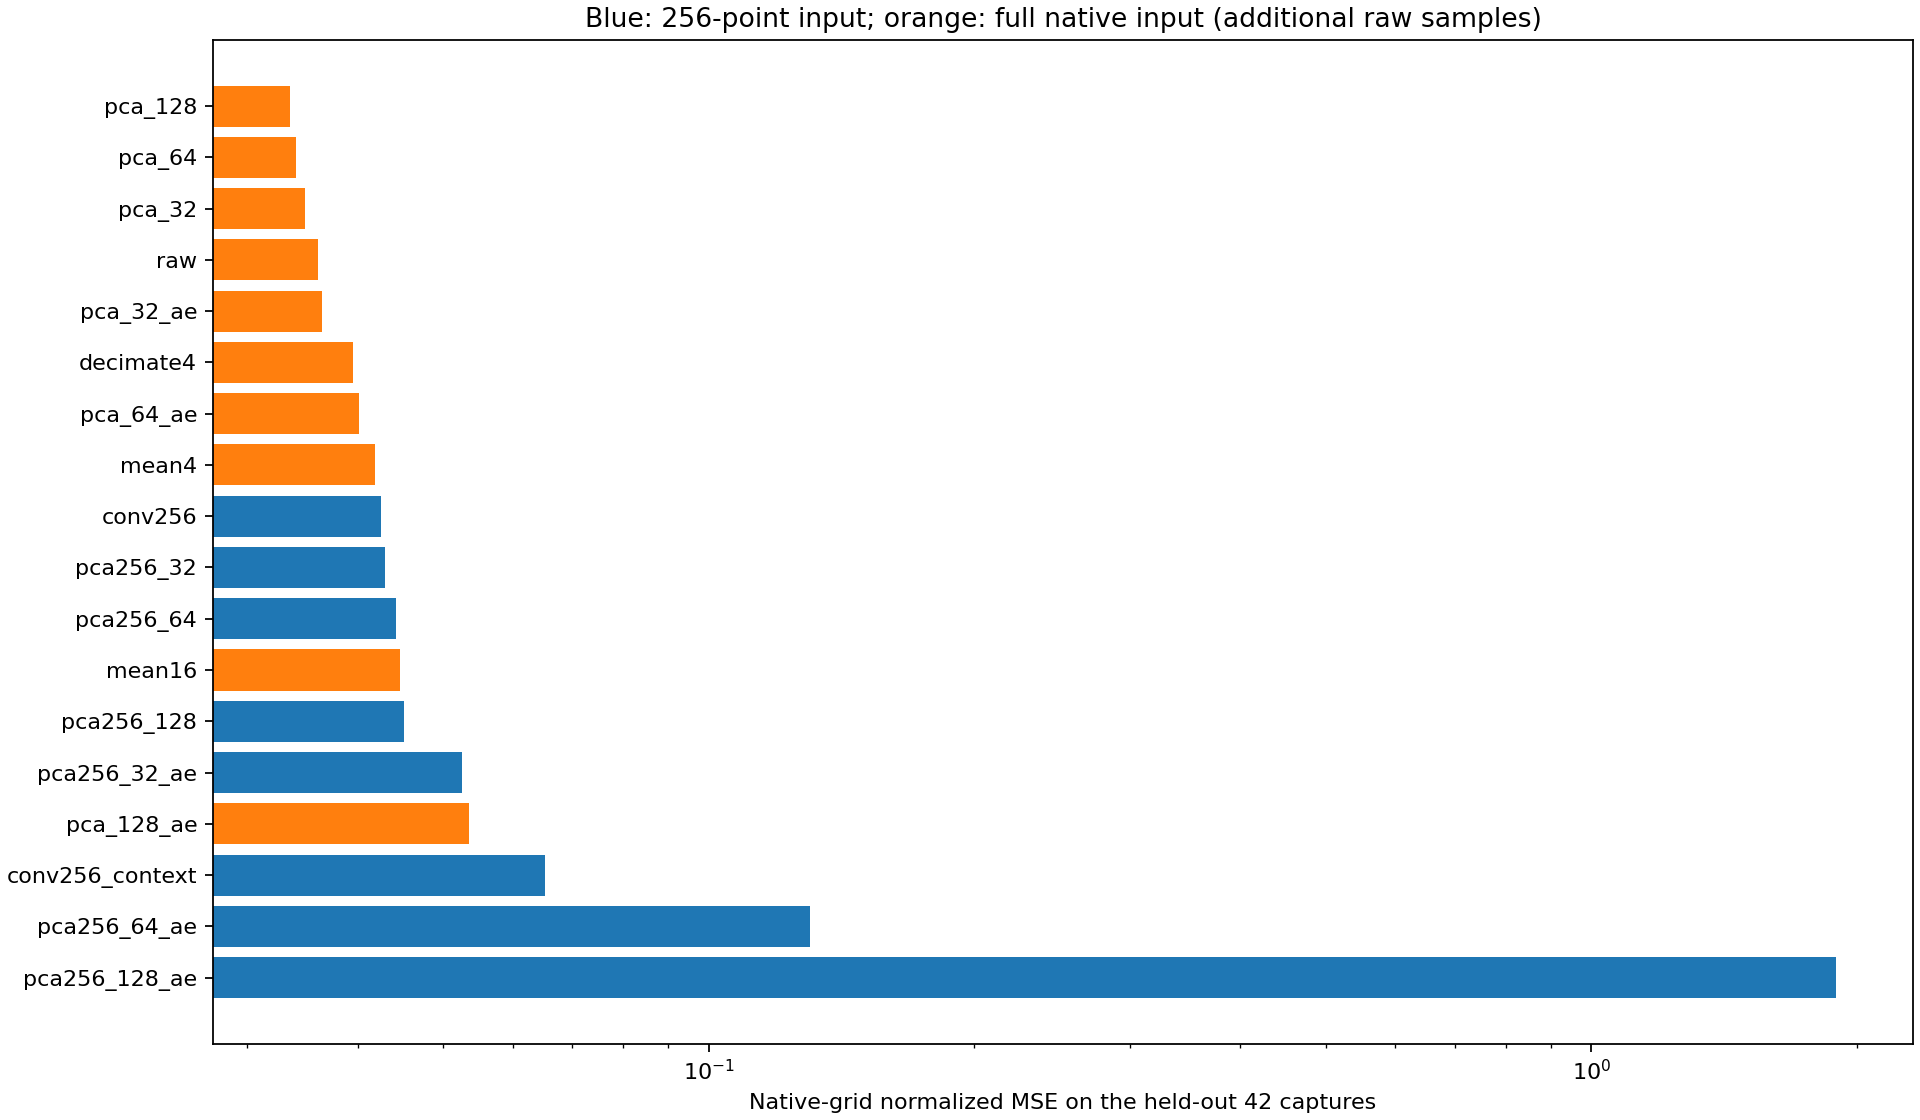

In [9]:
display(pd.read_csv(OUTPUT / "heldout_native_comparison.csv"))
display(Image(filename=str(OUTPUT / "heldout_native_comparison.png")))
